# pip install scikit-learn

In [4]:
pip install matplotlib

  Using cached matplotlib-3.10.9-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (52 kB)
  Using cached contourpy-1.3.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pillow-12.3.0-cp310-cp310-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
Using cached matplotlib-3.10.9-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (8.8 MB)
Using cached contourpy-1.3.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (325 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 136.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 111.4 MB/s  0:00:00
Using cached pillow-12.3.0-cp310-cp310-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (6.9 MB)
Using cached pyparsing-3.3.2-py3-none-any.whl (122 

Classes encontradas (ordem alfabética): ['BENIGN', 'MALIGNANT']
Classe positiva = 'MALIGNANT' (índice 1)
BENIGN: 43 imagens
MALIGNANT: 41 imagens
Total de imagens no teste: 84
Processadas 10/84 | falhas=0 | 4.7s
Processadas 20/84 | falhas=0 | 9.4s
Processadas 30/84 | falhas=0 | 13.8s
Processadas 40/84 | falhas=0 | 18.5s
Processadas 50/84 | falhas=0 | 22.9s
Processadas 60/84 | falhas=0 | 27.5s
Processadas 70/84 | falhas=0 | 31.9s
Processadas 80/84 | falhas=0 | 36.4s

Concluído. Predições coletadas: 84 | falhas: 0

================= MÉTRICAS (argmax) =================
Accuracy: 0.8333333333333334

Matriz de Confusão (linhas=true, colunas=pred):
 [[35  8]
 [ 6 35]]

Relatório por classe:

              precision    recall  f1-score   support

      BENIGN     0.8537    0.8140    0.8333        43
   MALIGNANT     0.8140    0.8537    0.8333        41

    accuracy                         0.8333        84
   macro avg     0.8338    0.8338    0.8333        84
weighted avg     0.8343    0.8333

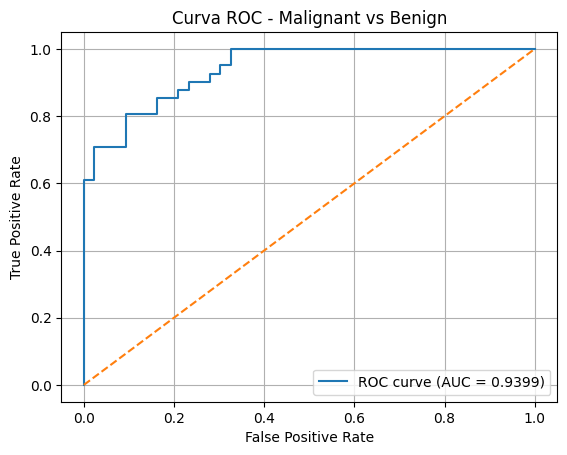

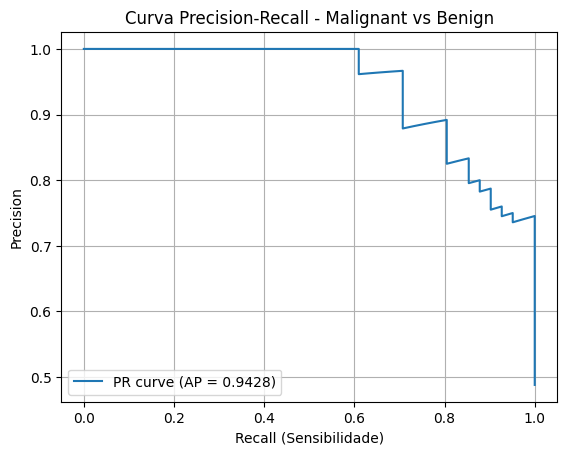

In [5]:
# = MÉTRICAS (Benign vs malignant) seu ENDPOINT + test/validation set no S3 

# Copie e cole no notebook do SageMaker Studio AI (Learner Lab)


import boto3
import json
import numpy as np
import time
import pandas as pd
from botocore.exceptions import ClientError
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# ---------------- CONFIG ----------------

#----JPG-----
ENDPOINT_NAME = "endpoint-jumpstart" # digite o nome do seu endpoint
TEST_S3_URI    = "s3://bucket-image-test-v2/dataset_lumbar/test/" # insira o conjunto de dados (test)
#--------------------

CONTENT_TYPE   = "application/x-image"

POSITIVE_LABEL = "malignant"   # classe positiva
MAX_IMAGES_PER_CLASS = None    # ex.: 200 para testar rápido, ou None para usar todas

MAX_RETRIES = 5                # retries para invoke_endpoint
PRINT_EVERY = 10               # progresso a cada N imagens
# ----------------------------------------


# --------- Helpers ----------
s3 = boto3.client("s3")
runtime = boto3.client("sagemaker-runtime")

def parse_s3_uri(uri: str):
    assert uri.startswith("s3://")
    b, k = uri[5:].split("/", 1)
    if k and not k.endswith("/"):
        k += "/"
    return b, k

def list_class_folders(bucket: str, prefix: str):
    # Pastas 1 nível abaixo do prefix (test/<classe>/)
    resp = s3.list_objects_v2(Bucket=bucket, Prefix=prefix, Delimiter="/")
    class_prefixes = resp.get("CommonPrefixes", [])
    class_names = []
    for cp in class_prefixes:
        p = cp["Prefix"]
        name = p[len(prefix):].strip("/").split("/")[0]
        if name:
            class_names.append(name)
    return sorted(class_names)

def list_images(bucket: str, prefix: str):
    keys = []
    token = None
    while True:
        kwargs = dict(Bucket=bucket, Prefix=prefix)
        if token:
            kwargs["ContinuationToken"] = token
        resp = s3.list_objects_v2(**kwargs)
        for obj in resp.get("Contents", []):
            k = obj["Key"]
            if k.lower().endswith((".jpg", ".jpeg")):
                keys.append(k)
        if resp.get("IsTruncated"):
            token = resp.get("NextContinuationToken")
        else:
            break
    return keys

def invoke_with_retries(image_bytes: bytes):
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            resp = runtime.invoke_endpoint(
                EndpointName=ENDPOINT_NAME,
                ContentType=CONTENT_TYPE,
                Body=image_bytes
            )
            result = json.loads(resp["Body"].read().decode())
            probs = np.array(result["probabilities"], dtype=float)
            return probs
        except Exception as e:
            if attempt == MAX_RETRIES:
                raise
            backoff = (2 ** (attempt - 1)) * 0.5
            print(f"[warn] invoke falhou (tentativa {attempt}/{MAX_RETRIES}): {e} | retry em {backoff:.1f}s")
            time.sleep(backoff)

# --------- 1) Listar classes e imagens do TEST ----------
test_bucket, test_prefix = parse_s3_uri(TEST_S3_URI)
classes = list_class_folders(test_bucket, test_prefix)

if not classes:
    raise RuntimeError(f"Não encontrei pastas de classe em {TEST_S3_URI}. Esperado: test/<classe>/*.jpg")

print("Classes encontradas (ordem alfabética):", classes)

# Mapas
label_to_idx = {c: i for i, c in enumerate(classes)}
idx_to_label = {i: c for c, i in label_to_idx.items()}

# Definir índice da classe positiva (malignant), case-insensitive
pos_idx = None
for c in classes:
    if c.lower() == POSITIVE_LABEL.lower():
        pos_idx = label_to_idx[c]
        break
if pos_idx is None:
    raise RuntimeError(f"Não achei a classe positiva '{POSITIVE_LABEL}' nas pastas: {classes}")

print(f"Classe positiva = '{idx_to_label[pos_idx]}' (índice {pos_idx})")

# Montar lista completa (key, y_true)
all_keys = []
all_y_true = []

for c in classes:
    cls_prefix = f"{test_prefix}{c}/"
    keys = list_images(test_bucket, cls_prefix)
    if MAX_IMAGES_PER_CLASS is not None:
        keys = keys[:MAX_IMAGES_PER_CLASS]
    print(f"{c}: {len(keys)} imagens")
    all_keys.extend(keys)
    all_y_true.extend([label_to_idx[c]] * len(keys))

all_y_true = np.array(all_y_true, dtype=int)
print("Total de imagens no teste:", len(all_keys))

if len(all_keys) == 0:
    raise RuntimeError("Nenhuma imagem JPG encontrada no test set.")

# --------- 2) Inferência no endpoint ----------
all_probs = []
kept_keys = []
kept_y_true = []

failed = 0
t0 = time.time()

for i, (key, y) in enumerate(zip(all_keys, all_y_true), 1):
    try:
        img_bytes = s3.get_object(Bucket=test_bucket, Key=key)["Body"].read()
        probs = invoke_with_retries(img_bytes)

        all_probs.append(probs)
        kept_keys.append(key)
        kept_y_true.append(y)
    except Exception as e:
        failed += 1
        print(f"[erro] Falhou na imagem: {key} | {e}")

    if i % PRINT_EVERY == 0:
        elapsed = time.time() - t0
        print(f"Processadas {i}/{len(all_keys)} | falhas={failed} | {elapsed:.1f}s")

all_probs = np.vstack(all_probs)
kept_y_true = np.array(kept_y_true, dtype=int)

print(f"\nConcluído. Predições coletadas: {len(kept_keys)} | falhas: {failed}")

# --------- 3) Métricas ----------
y_pred = all_probs.argmax(axis=1)

acc = accuracy_score(kept_y_true, y_pred)
cm = confusion_matrix(kept_y_true, y_pred)

print("\n================= MÉTRICAS (argmax) =================")
print("Accuracy:", acc)
print("\nMatriz de Confusão (linhas=true, colunas=pred):\n", cm)

target_names = [idx_to_label[i] for i in range(len(classes))]
print("\nRelatório por classe:\n")
print(classification_report(kept_y_true, y_pred, target_names=target_names, digits=4))

# Binário com malignant como positivo (AUC, PR AUC, sensibilidade, especificidade)
y_true_bin = (kept_y_true == pos_idx).astype(int)
y_pred_bin = (y_pred == pos_idx).astype(int)
cm_bin = confusion_matrix(y_true_bin, y_pred_bin)
tn, fp, fn, tp = cm_bin.ravel()

sens = tp / (tp + fn) if (tp + fn) else float("nan")  # recall malignant
spec = tn / (tn + fp) if (tn + fp) else float("nan")

y_score = all_probs[:, pos_idx]  # probabilidade de malignant
auc = roc_auc_score(y_true_bin, y_score)
ap  = average_precision_score(y_true_bin, y_score)

print("\n=========== BINÁRIO (malignant positivo) ===========")
print("ROC AUC:", auc)
print("PR AUC (Average Precision):", ap)
print("Sensibilidade / Recall (malignant):", sens)
print("Especificidade:", spec)
print("CM binária [[TN,FP],[FN,TP]]:\n", cm_bin)

# --------- 4) Salvar CSV com resultados ----------
df = pd.DataFrame({
    "s3_key": kept_keys,
    "y_true_idx": kept_y_true,
    "y_true_label": [idx_to_label[i] for i in kept_y_true],
    "y_pred_idx": y_pred,
    "y_pred_label": [idx_to_label[i] for i in y_pred],
})

for i, name in enumerate(target_names):
    df[f"prob_{name}"] = all_probs[:, i]

out_csv = "metrics_validation_predictions.csv"
df.to_csv(out_csv, index=False)
print("\nCSV salvo:", out_csv)


# ROC

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

# ROC
fpr, tpr, thresholds = roc_curve(y_true_bin, y_score)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC - Malignant vs Benign")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Precision-Recall
precision, recall, thresholds_pr = precision_recall_curve(y_true_bin, y_score)

plt.figure()
plt.plot(recall, precision, label=f"PR curve (AP = {ap:.4f})")
plt.xlabel("Recall (Sensibilidade)")
plt.ylabel("Precision")
plt.title("Curva Precision-Recall - Malignant vs Benign")
plt.legend(loc="lower left")
plt.grid(True)
plt.show()